In [1]:
!pip install -q -U kagglehub grad-cam gradio
print("Packages installed.")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.5/44.5 kB 4.4 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 31.4/31.4 MB 41.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 64.5/64.5 kB 2.6 MB/s eta 0:00:00
Packages installed.


In [2]:
import os, random, json, math, time, shutil
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import models
from sklearn.metrics import f1_score, accuracy_score, classification_report, roc_auc_score
from sklearn.model_selection import train_test_split

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", DEVICE)
if DEVICE.type == "cpu":
    print("WARNING: no GPU detected. Go to Runtime -> Change runtime type -> T4 GPU, then Run all again.")

Using device: cuda


## 2. Configuration

`SUBSET_SIZE` is how many images are used in total (train + val + test). 3000 fits comfortably in free Colab RAM and trains fast.
Set it to `None` to use the full dataset (about 10,000 images). That needs roughly 3 GB of RAM and takes several times longer, so raise it gradually (e.g. 5000) rather than jumping straight to the max.

In [3]:
SUBSET_SIZE   = 3000     # None = use everything available
IMG_SIZE      = 256      # used for both segmentation and classification
BATCH_SIZE    = 16
SEG_EPOCHS    = 15
CLS_EPOCHS    = 12
LR_SEG        = 1e-3
LR_CLS        = 3e-4
VAL_SPLIT     = 0.15
TEST_SPLIT    = 0.15
RUN_MASK_GUIDED_ABLATION = True   # also trains a classifier that only sees the segmented lesion
SAVE_TO_DRIVE = True              # back up trained models to Google Drive (so you can reuse them tomorrow)
DRIVE_FOLDER  = "/content/drive/MyDrive/SkinLesionProject"

# If you already have the dataset somewhere (Drive, Colab "Add data"), put its folder here to skip the download:
DATASET_PATH_OVERRIDE = None

# "auto"  = if your trained models are already on Google Drive -> skip training and just launch the app; otherwise train.
# "train" = always train.   "demo" = never train (load saved models, upload them if they are not on Drive).
MODE = "auto"

## 2b. Connect Google Drive (so your trained models survive after this session)

A pop-up will ask you to allow Drive access. Click through it once now. Models are copied to the `SkinLesionProject` folder in your Drive right after each training stage.

In [4]:
def backup(*files):
    """Copy files to Google Drive (no-op if Drive is disabled/unavailable)."""
    if not (SAVE_TO_DRIVE and os.path.isdir(DRIVE_FOLDER)):
        return
    for f in files:
        if os.path.exists(f):
            shutil.copy(f, DRIVE_FOLDER)
            print("  backed up to Drive:", os.path.basename(f))

if SAVE_TO_DRIVE:
    try:
        from google.colab import drive
        drive.mount("/content/drive")
        os.makedirs(DRIVE_FOLDER, exist_ok=True)
        print("Drive connected. Models will be saved to:", DRIVE_FOLDER)
    except Exception as e:
        print("Could not connect Drive:", repr(e))
        print("Training will still work, but download the .pt files manually at the end.")

Mounted at /content/drive
Drive connected. Models will be saved to: /content/drive/MyDrive/SkinLesionProject


In [5]:
NEEDED = ["unet_best.pt", "efficientnet_baseline_best.pt", "model_meta.json"]

def drive_has_models():
    return os.path.isdir(DRIVE_FOLDER) and all(os.path.exists(os.path.join(DRIVE_FOLDER, f)) for f in NEEDED)

if MODE == "train":
    DEMO_MODE = False
elif MODE == "demo":
    DEMO_MODE = True
else:
    DEMO_MODE = drive_has_models()

print("=" * 60)
if DEMO_MODE:
    print("DEMO MODE: saved models found -> skipping training, loading them and launching the app.")
else:
    print("TRAIN MODE: no saved models found -> training now (models are saved to Drive automatically).")
print("=" * 60)

TRAIN MODE: no saved models found -> training now (models are saved to Drive automatically).


## 3. Kaggle login + dataset download

You need a Kaggle API token. Get it at kaggle.com → profile picture → **Settings** → **API** → **Create New Token**.

You can paste in whichever form Kaggle gave you:
- A **single long token string** (often starts with `KGAT_`): paste it when asked, no username needed.
- An older-style **username + key** pair: paste the key, then type your username when asked.

The token is only held in this session's memory. Never share it or commit it to GitHub.

In [6]:
if not DEMO_MODE:   # training only (skipped when saved models are found)
    from getpass import getpass

    def have_creds():
        return bool(os.environ.get("KAGGLE_API_TOKEN") or
                    (os.environ.get("KAGGLE_USERNAME") and os.environ.get("KAGGLE_KEY")))

    # 1) try Colab "Secrets" (key icon in the left sidebar) if the user stored them there
    if not have_creds():
        try:
            from google.colab import userdata
            for k in ("KAGGLE_API_TOKEN", "KAGGLE_USERNAME", "KAGGLE_KEY"):
                try:
                    v = userdata.get(k)
                    if v: os.environ[k] = v
                except Exception:
                    pass
        except Exception:
            pass

    # 2) otherwise ask
    if not have_creds() and DATASET_PATH_OVERRIDE is None:
        secret = getpass("Paste your Kaggle API token / key (input is hidden): ").strip()
        if secret.startswith("KGAT_"):
            os.environ["KAGGLE_API_TOKEN"] = secret
        else:
            os.environ["KAGGLE_USERNAME"] = input("Kaggle username: ").strip()
            os.environ["KAGGLE_KEY"] = secret
    print("Credentials ready:", have_creds() or DATASET_PATH_OVERRIDE is not None)

Paste your Kaggle API token / key (input is hidden): ··········
Credentials ready: True


In [7]:
if not DEMO_MODE:   # training only (skipped when saved models are found)
    import kagglehub

    if DATASET_PATH_OVERRIDE:
        dataset_path = DATASET_PATH_OVERRIDE
    else:
        try:
            dataset_path = kagglehub.dataset_download("surajghuwalewala/ham1000-segmentation-and-classification")
        except Exception as e:
            print("Download failed:", repr(e))
            print("\nCommon fixes:")
            print(" - Open the dataset page on kaggle.com while logged in and accept any terms shown, then re-run this cell.")
            print(" - Check the token was pasted completely (no spaces / quotes).")
            print(" - Run  !pip install -U kagglehub  and then Runtime -> Restart session, and re-run from the top.")
            raise

    print("Dataset at:", dataset_path)
    for root, dirs, fs in os.walk(dataset_path):
        depth = os.path.relpath(root, dataset_path).count(os.sep)
        if depth <= 2:
            print(f"{root}  ->  {len(fs)} files")

100%|██████████| 2.59G/2.59G [00:24<00:00, 112MB/s] 

Extracting files...


Dataset at: /root/.cache/kagglehub/datasets/surajghuwalewala/ham1000-segmentation-and-classification/versions/2
/root/.cache/kagglehub/datasets/surajghuwalewala/ham1000-segmentation-and-classification/versions/2  ->  1 files
/root/.cache/kagglehub/datasets/surajghuwalewala/ham1000-segmentation-and-classification/versions/2/images  ->  10017 files
/root/.cache/kagglehub/datasets/surajghuwalewala/ham1000-segmentation-and-classification/versions/2/masks  ->  10015 files


## 4. Index images, masks and labels

The code detects masks (files ending in `_segmentation`, or inside a folder named like `masks`), finds the labels CSV, and keeps only IDs that have an image, a mask **and** a label.
It handles both common CSV layouts: one-hot columns (MEL, NV, BCC, ...) or a single `dx` column.

In [8]:
if not DEMO_MODE:   # training only (skipped when saved models are found)
    IMG_EXT = (".jpg", ".jpeg", ".png")

    def index_images(base):
        images, masks = {}, {}
        for root, _, fs in os.walk(base):
            parent = os.path.basename(root).lower()
            for f in fs:
                if not f.lower().endswith(IMG_EXT):
                    continue
                stem = os.path.splitext(f)[0]
                has_suffix = stem.lower().endswith("_segmentation")
                is_mask = has_suffix or ("mask" in parent) or ("segmentation" in parent)
                key = stem[:-len("_segmentation")] if has_suffix else stem
                (masks if is_mask else images)[key] = os.path.join(root, f)
        return images, masks

    def load_labels(base):
        for root, _, fs in os.walk(base):
            for f in fs:
                if not f.lower().endswith(".csv"):
                    continue
                df = pd.read_csv(os.path.join(root, f))
                cols = {c.lower(): c for c in df.columns}
                id_col = cols.get("image") or cols.get("image_id")
                if id_col is None:
                    continue
                if "dx" in cols:
                    names = sorted(df[cols["dx"]].astype(str).unique())
                    mapping = {n: i for i, n in enumerate(names)}
                    labels = {str(r[id_col]): mapping[str(r[cols["dx"]])] for _, r in df.iterrows()}
                    return labels, names, os.path.join(root, f)
                onehot = [c for c in df.columns
                          if c != id_col and pd.api.types.is_numeric_dtype(df[c])
                          and set(df[c].dropna().unique()) <= {0, 1, 0.0, 1.0}]
                if len(onehot) >= 2:
                    idx = df[onehot].values.argmax(axis=1)
                    labels = {str(i): int(l) for i, l in zip(df[id_col], idx)}
                    return labels, [c.upper() for c in onehot], os.path.join(root, f)
        return None, None, None

    images, masks = index_images(dataset_path)
    labels, CLASS_NAMES, csv_used = load_labels(dataset_path)
    print(f"images found: {len(images)} | masks found: {len(masks)} | labels csv: {csv_used}")

    if not images or not masks or labels is None:
        print("\nCould not auto-detect the dataset layout. Folder overview:")
        for root, dirs, fs in os.walk(dataset_path):
            print(root, "->", len(fs), "files", fs[:3])
        raise RuntimeError("Dataset layout not recognised. Share the folder overview above and the loader can be adjusted.")

    ids = sorted(set(images) & set(masks) & set(labels))
    print("Usable (image + mask + label) samples:", len(ids))
    print("Classes:", CLASS_NAMES)

    records = [{"id": i, "image": images[i], "mask": masks[i], "label": labels[i]} for i in ids]
    random.Random(SEED).shuffle(records)
    if SUBSET_SIZE:
        records = records[:SUBSET_SIZE]
    print("Using", len(records), "samples")
    print(pd.Series([CLASS_NAMES[r["label"]] for r in records]).value_counts())

images found: 10015 | masks found: 10015 | labels csv: /root/.cache/kagglehub/datasets/surajghuwalewala/ham1000-segmentation-and-classification/versions/2/GroundTruth.csv
Usable (image + mask + label) samples: 10015
Classes: ['MEL', 'NV', 'BCC', 'AKIEC', 'BKL', 'DF', 'VASC']
Using 3000 samples
NV       2018
BKL       335
MEL       329
BCC       143
AKIEC      96
VASC       43
DF         36
Name: count, dtype: int64


In [9]:
if not DEMO_MODE:   # training only (skipped when saved models are found)
    def safe_split(items, test_size):
        try:
            return train_test_split(items, test_size=test_size, random_state=SEED,
                                    stratify=[x["label"] for x in items])
        except ValueError:  # a class too rare to stratify
            return train_test_split(items, test_size=test_size, random_state=SEED)

    rest, test_records = safe_split(records, TEST_SPLIT)
    train_records, val_records = safe_split(rest, VAL_SPLIT / (1 - TEST_SPLIT))
    print(f"train={len(train_records)}  val={len(val_records)}  test={len(test_records)}")

train=2099  val=451  test=450


**Note on leakage:** HAM10000 contains several photos of the same lesion. This split is by image (stratified by class), so near-duplicate lesions can appear in both train and test and slightly inflate scores. A split by `lesion_id` is stricter. Mention this in your write-up as a limitation.

## 5. Dataset (images are cached in RAM once, so training is fast)

In [10]:
if not DEMO_MODE:   # training only (skipped when saved models are found)
    class LesionDataset(Dataset):
        def __init__(self, records, augment=False):
            self.augment = augment
            imgs, msks, labs, ids = [], [], [], []
            skipped = 0
            for r in records:
                im = cv2.imread(r["image"]); mk = cv2.imread(r["mask"], cv2.IMREAD_GRAYSCALE)
                if im is None or mk is None:
                    skipped += 1; continue
                im = cv2.cvtColor(im, cv2.COLOR_BGR2RGB)
                im = cv2.resize(im, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_AREA)
                mk = cv2.resize(mk, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_NEAREST)
                imgs.append(im); msks.append((mk > 127).astype(np.uint8))
                labs.append(r["label"]); ids.append(r["id"])
            if skipped: print("Skipped unreadable files:", skipped)
            self.imgs, self.masks = np.stack(imgs), np.stack(msks)
            self.labels, self.ids = labs, ids

        def __len__(self): return len(self.labels)

        def __getitem__(self, i):
            img = torch.from_numpy(self.imgs[i]).permute(2, 0, 1).float() / 255.0
            mask = torch.from_numpy(self.masks[i]).unsqueeze(0).float()
            if self.augment:
                if random.random() < 0.5: img, mask = img.flip(-1), mask.flip(-1)
                if random.random() < 0.5: img, mask = img.flip(-2), mask.flip(-2)
                img = (img * (0.85 + 0.3 * random.random())).clamp(0, 1)
            return img, mask, self.labels[i]

    t0 = time.time()
    train_ds = LesionDataset(train_records, augment=True)
    val_ds   = LesionDataset(val_records)
    test_ds  = LesionDataset(test_records)
    print(f"Loaded in {time.time()-t0:.0f}s")

    train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True)
    val_loader   = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False)
    test_loader  = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False)

Loaded in 29s


## 6. Segmentation: U-Net

In [11]:
class DoubleConv(nn.Module):
    def __init__(self, i, o):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(i, o, 3, padding=1), nn.BatchNorm2d(o), nn.ReLU(inplace=True),
            nn.Conv2d(o, o, 3, padding=1), nn.BatchNorm2d(o), nn.ReLU(inplace=True))
    def forward(self, x): return self.net(x)

class UNet(nn.Module):
    def __init__(self, in_c=3, out_c=1, b=32):
        super().__init__()
        self.e1, self.e2 = DoubleConv(in_c, b), DoubleConv(b, b*2)
        self.e3, self.e4 = DoubleConv(b*2, b*4), DoubleConv(b*4, b*8)
        self.pool = nn.MaxPool2d(2)
        self.bott = DoubleConv(b*8, b*16)
        self.u4, self.d4 = nn.ConvTranspose2d(b*16, b*8, 2, 2), DoubleConv(b*16, b*8)
        self.u3, self.d3 = nn.ConvTranspose2d(b*8, b*4, 2, 2), DoubleConv(b*8, b*4)
        self.u2, self.d2 = nn.ConvTranspose2d(b*4, b*2, 2, 2), DoubleConv(b*4, b*2)
        self.u1, self.d1 = nn.ConvTranspose2d(b*2, b, 2, 2), DoubleConv(b*2, b)
        self.out = nn.Conv2d(b, out_c, 1)

    def forward(self, x):
        e1 = self.e1(x); e2 = self.e2(self.pool(e1))
        e3 = self.e3(self.pool(e2)); e4 = self.e4(self.pool(e3))
        b = self.bott(self.pool(e4))
        d4 = self.d4(torch.cat([self.u4(b), e4], 1))
        d3 = self.d3(torch.cat([self.u3(d4), e3], 1))
        d2 = self.d2(torch.cat([self.u2(d3), e2], 1))
        d1 = self.d1(torch.cat([self.u1(d2), e1], 1))
        return self.out(d1)

def dice_loss(logits, target, eps=1e-6):
    p = torch.sigmoid(logits)
    inter = (p * target).sum((1, 2, 3)); tot = p.sum((1, 2, 3)) + target.sum((1, 2, 3))
    return 1 - ((2 * inter + eps) / (tot + eps)).mean()

def seg_loss(logits, target):
    return F.binary_cross_entropy_with_logits(logits, target) + dice_loss(logits, target)

def seg_metrics(logits, target, eps=1e-6):
    p = (torch.sigmoid(logits) > 0.5).float()
    inter = (p * target).sum((1, 2, 3))
    dice = ((2 * inter + eps) / (p.sum((1, 2, 3)) + target.sum((1, 2, 3)) + eps)).mean().item()
    iou = ((inter + eps) / ((p + target).clamp(0, 1).sum((1, 2, 3)) + eps)).mean().item()
    return dice, iou

seg_model = UNet().to(DEVICE)
print(f"U-Net parameters: {sum(p.numel() for p in seg_model.parameters())/1e6:.1f}M")

U-Net parameters: 7.8M


### Train the segmentation model

In [12]:
if not DEMO_MODE:   # training only (skipped when saved models are found)
    opt = torch.optim.Adam(seg_model.parameters(), lr=LR_SEG)
    sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, mode="max", patience=2, factor=0.5)
    seg_hist = {"train_loss": [], "val_loss": [], "val_dice": [], "val_iou": []}
    best_dice = -1

    for ep in range(SEG_EPOCHS):
        seg_model.train(); run = 0.0
        for img, mask, _ in train_loader:
            img, mask = img.to(DEVICE), mask.to(DEVICE)
            opt.zero_grad()
            loss = seg_loss(seg_model(img), mask)
            loss.backward(); opt.step()
            run += loss.item() * img.size(0)
        tl = run / len(train_ds)

        seg_model.eval(); vl = vd = vi = 0.0
        with torch.no_grad():
            for img, mask, _ in val_loader:
                img, mask = img.to(DEVICE), mask.to(DEVICE)
                out = seg_model(img)
                d, i = seg_metrics(out, mask)
                vl += seg_loss(out, mask).item(); vd += d; vi += i
        n = len(val_loader); vl, vd, vi = vl/n, vd/n, vi/n
        sched.step(vd)
        for k, v in zip(seg_hist, (tl, vl, vd, vi)): seg_hist[k].append(v)
        print(f"[Seg] epoch {ep+1:02d}/{SEG_EPOCHS}  train_loss {tl:.4f}  val_dice {vd:.4f}  val_iou {vi:.4f}")
        if vd > best_dice:
            best_dice = vd; torch.save(seg_model.state_dict(), "unet_best.pt")

    seg_model.load_state_dict(torch.load("unet_best.pt", map_location=DEVICE)); seg_model.eval()
    print("Best val Dice:", round(best_dice, 4))
    backup("unet_best.pt")

[Seg] epoch 01/15  train_loss 0.7567  val_dice 0.7757  val_iou 0.6715
[Seg] epoch 02/15  train_loss 0.5040  val_dice 0.8291  val_iou 0.7413
[Seg] epoch 03/15  train_loss 0.4474  val_dice 0.8370  val_iou 0.7480
[Seg] epoch 04/15  train_loss 0.3939  val_dice 0.8507  val_iou 0.7683
[Seg] epoch 05/15  train_loss 0.3729  val_dice 0.8600  val_iou 0.7828
[Seg] epoch 06/15  train_loss 0.3644  val_dice 0.8617  val_iou 0.7801
[Seg] epoch 07/15  train_loss 0.3500  val_dice 0.8496  val_iou 0.7676
[Seg] epoch 08/15  train_loss 0.3369  val_dice 0.8676  val_iou 0.7927
[Seg] epoch 09/15  train_loss 0.3363  val_dice 0.8549  val_iou 0.7755
[Seg] epoch 10/15  train_loss 0.3351  val_dice 0.8645  val_iou 0.7907
[Seg] epoch 11/15  train_loss 0.3194  val_dice 0.8658  val_iou 0.7892
[Seg] epoch 12/15  train_loss 0.2963  val_dice 0.8800  val_iou 0.8102
[Seg] epoch 13/15  train_loss 0.2862  val_dice 0.8720  val_iou 0.8009
[Seg] epoch 14/15  train_loss 0.2842  val_dice 0.8758  val_iou 0.8050
[Seg] epoch 15/15  t

TEST  Dice 0.8972 | IoU 0.8316


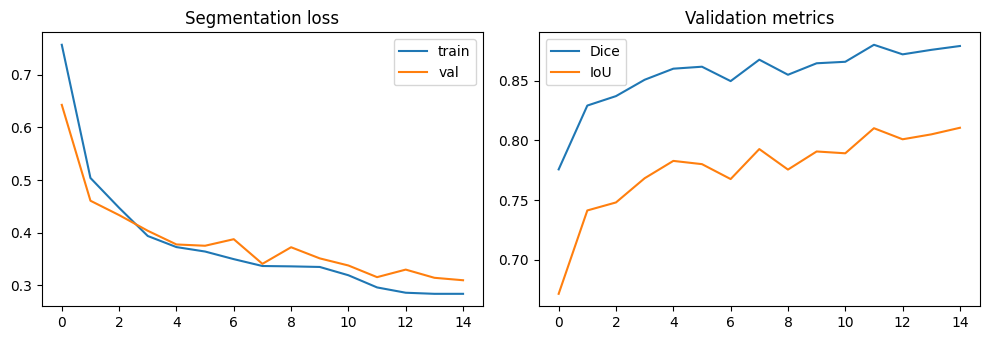

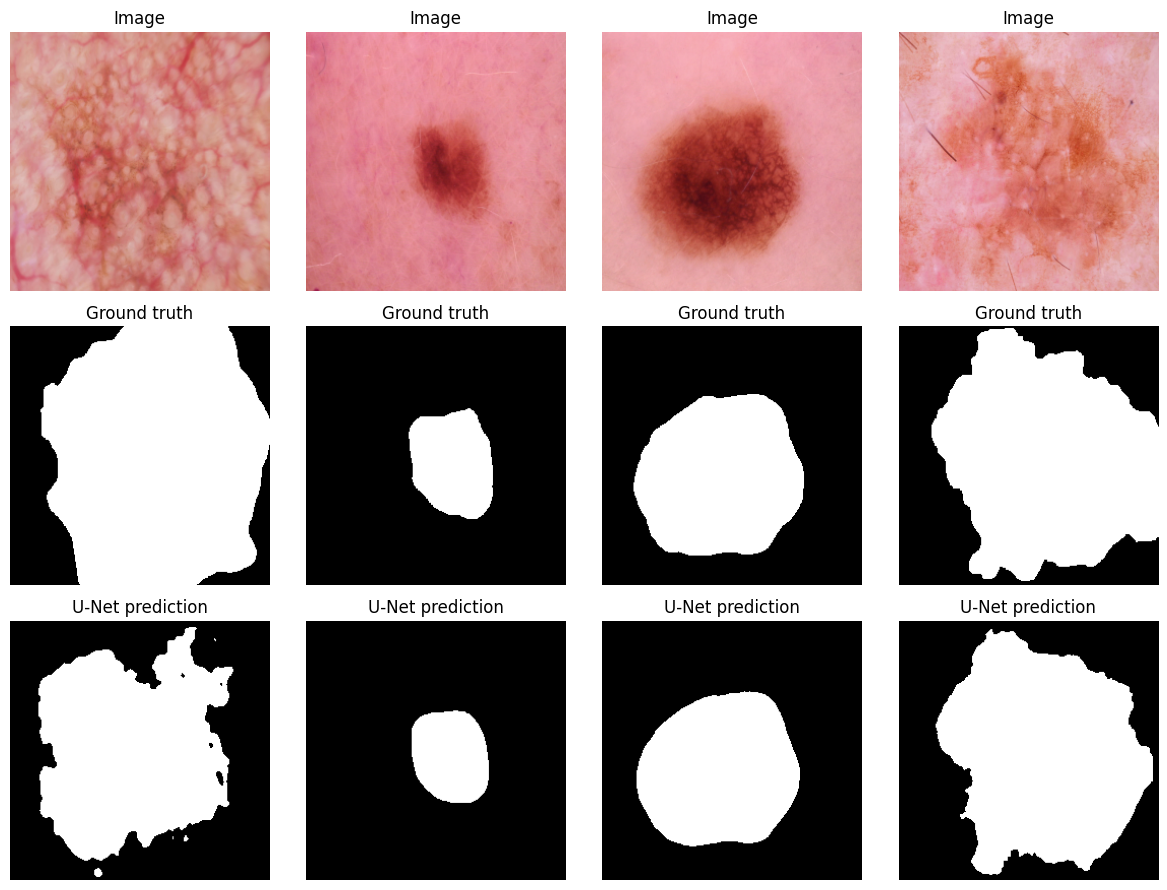

In [13]:
if not DEMO_MODE:   # training only (skipped when saved models are found)
    # Test-set segmentation score + qualitative examples
    td = ti = 0.0
    with torch.no_grad():
        for img, mask, _ in test_loader:
            d, i = seg_metrics(seg_model(img.to(DEVICE)), mask.to(DEVICE))
            td += d; ti += i
    test_dice, test_iou = td/len(test_loader), ti/len(test_loader)
    print(f"TEST  Dice {test_dice:.4f} | IoU {test_iou:.4f}")

    plt.figure(figsize=(10, 3.5))
    plt.subplot(1, 2, 1); plt.plot(seg_hist["train_loss"], label="train"); plt.plot(seg_hist["val_loss"], label="val"); plt.title("Segmentation loss"); plt.legend()
    plt.subplot(1, 2, 2); plt.plot(seg_hist["val_dice"], label="Dice"); plt.plot(seg_hist["val_iou"], label="IoU"); plt.title("Validation metrics"); plt.legend()
    plt.tight_layout(); plt.show()

    img, mask, _ = next(iter(test_loader))
    with torch.no_grad():
        pm = (torch.sigmoid(seg_model(img.to(DEVICE))) > 0.5).float().cpu()
    fig, ax = plt.subplots(3, 4, figsize=(12, 9))
    for k in range(4):
        ax[0, k].imshow(img[k].permute(1, 2, 0)); ax[0, k].set_title("Image")
        ax[1, k].imshow(mask[k, 0], cmap="gray"); ax[1, k].set_title("Ground truth")
        ax[2, k].imshow(pm[k, 0], cmap="gray"); ax[2, k].set_title("U-Net prediction")
        for r in range(3): ax[r, k].axis("off")
    plt.tight_layout(); plt.show()

## 7. Classification: EfficientNet-B0 (ImageNet-pretrained)

ImageNet normalisation lives *inside* the model, so everywhere else we can feed plain `[0, 1]` images (this also keeps Grad-CAM and the web app simple).

HAM10000 is heavily imbalanced (most images are benign nevi), so the loss is class-weighted and we track **macro-F1** rather than accuracy alone.

In [14]:
class SkinClassifier(nn.Module):
    def __init__(self, n_classes, pretrained=True):
        super().__init__()
        self.net = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.IMAGENET1K_V1 if pretrained else None)
        self.net.classifier[1] = nn.Linear(self.net.classifier[1].in_features, n_classes)
        self.register_buffer("mean", torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1))
        self.register_buffer("std", torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1))
    def forward(self, x):
        return self.net((x - self.mean) / self.std)

In [15]:
if not DEMO_MODE:   # training only (skipped when saved models are found)
    N_CLS = len(CLASS_NAMES)
    counts = np.bincount([r["label"] for r in train_records], minlength=N_CLS)
    class_weights = torch.tensor(len(train_records) / (N_CLS * np.maximum(counts, 1)), dtype=torch.float).to(DEVICE)
    print("Train class counts:", dict(zip(CLASS_NAMES, counts.tolist())))

    def build_input(imgs, masks, mode):
        return imgs * masks if mode == "masked" else imgs

    def predict_cls(model, loader, mode="plain"):
        """mode='masked' uses the U-Net's *predicted* lesion mask (no ground truth leakage)."""
        model.eval(); L, P, PR = [], [], []
        with torch.no_grad():
            for imgs, _, labels in loader:
                imgs = imgs.to(DEVICE)
                if mode == "masked":
                    m = (torch.sigmoid(seg_model(imgs)) > 0.5).float()
                    imgs = imgs * m
                out = model(imgs)
                PR.append(F.softmax(out, 1).cpu().numpy()); P.extend(out.argmax(1).cpu().numpy()); L.extend(labels.numpy())
        return np.array(L), np.array(P), np.concatenate(PR)

    def train_classifier(tag, mode):
        model = SkinClassifier(N_CLS).to(DEVICE)
        opt = torch.optim.Adam(model.parameters(), lr=LR_CLS)
        crit = nn.CrossEntropyLoss(weight=class_weights)
        sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, mode="max", patience=2, factor=0.5)
        best, hist = -1, {"val_acc": [], "val_f1": []}
        for ep in range(CLS_EPOCHS):
            model.train(); run = 0.0
            for imgs, masks, labels in train_loader:
                imgs, masks, labels = imgs.to(DEVICE), masks.to(DEVICE), labels.to(DEVICE)
                opt.zero_grad()
                loss = crit(model(build_input(imgs, masks, mode)), labels)   # train with ground-truth masks
                loss.backward(); opt.step(); run += loss.item() * imgs.size(0)
            L, P, _ = predict_cls(model, val_loader, mode)
            acc, f1 = accuracy_score(L, P), f1_score(L, P, average="macro")
            sched.step(f1); hist["val_acc"].append(acc); hist["val_f1"].append(f1)
            print(f"[{tag}] epoch {ep+1:02d}/{CLS_EPOCHS}  train_loss {run/len(train_ds):.4f}  val_acc {acc:.4f}  val_macroF1 {f1:.4f}")
            if f1 > best:
                best = f1; torch.save(model.state_dict(), f"{tag}_best.pt")
        model.load_state_dict(torch.load(f"{tag}_best.pt", map_location=DEVICE)); model.eval()
        return model, hist, best

Train class counts: {'MEL': 230, 'NV': 1412, 'BCC': 100, 'AKIEC': 67, 'BKL': 235, 'DF': 25, 'VASC': 30}


### Train the baseline classifier (full image)

In [16]:
if not DEMO_MODE:   # training only (skipped when saved models are found)
    cls_model, cls_hist, cls_best = train_classifier("efficientnet_baseline", "plain")
    print("Best val macro-F1:", round(cls_best, 4))
    backup("efficientnet_baseline_best.pt")
    json.dump({"class_names": CLASS_NAMES, "img_size": IMG_SIZE}, open("model_meta.json", "w"))
    backup("model_meta.json")

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 144MB/s]


[efficientnet_baseline] epoch 01/12  train_loss 1.4229  val_acc 0.6341  val_macroF1 0.5007
[efficientnet_baseline] epoch 02/12  train_loss 1.0242  val_acc 0.6408  val_macroF1 0.4977
[efficientnet_baseline] epoch 03/12  train_loss 0.7528  val_acc 0.6475  val_macroF1 0.5085
[efficientnet_baseline] epoch 04/12  train_loss 0.6327  val_acc 0.6785  val_macroF1 0.5229
[efficientnet_baseline] epoch 05/12  train_loss 0.5392  val_acc 0.7317  val_macroF1 0.5994
[efficientnet_baseline] epoch 06/12  train_loss 0.4343  val_acc 0.7494  val_macroF1 0.6430
[efficientnet_baseline] epoch 07/12  train_loss 0.3618  val_acc 0.7805  val_macroF1 0.6769
[efficientnet_baseline] epoch 08/12  train_loss 0.3265  val_acc 0.7494  val_macroF1 0.6422
[efficientnet_baseline] epoch 09/12  train_loss 0.4829  val_acc 0.6585  val_macroF1 0.4777
[efficientnet_baseline] epoch 10/12  train_loss 0.3533  val_acc 0.7406  val_macroF1 0.6471
[efficientnet_baseline] epoch 11/12  train_loss 0.1808  val_acc 0.7694  val_macroF1 0.6776

### Train the mask-guided classifier (ablation)

Same network, but it only sees the lesion (background multiplied by the mask). At validation/test time the mask comes from **your U-Net**, not the ground truth. Comparing the two answers a real question: *does segmentation actually help classification?*

In [17]:
if not DEMO_MODE:   # training only (skipped when saved models are found)
    if RUN_MASK_GUIDED_ABLATION:
        cls_model_masked, masked_hist, masked_best = train_classifier("efficientnet_masked", "masked")
        print("Best val macro-F1 (mask-guided):", round(masked_best, 4))
    else:
        cls_model_masked = None
        print("Ablation skipped.")

[efficientnet_masked] epoch 01/12  train_loss 1.5347  val_acc 0.4967  val_macroF1 0.3415
[efficientnet_masked] epoch 02/12  train_loss 1.1592  val_acc 0.6186  val_macroF1 0.4541
[efficientnet_masked] epoch 03/12  train_loss 1.0218  val_acc 0.6253  val_macroF1 0.5074
[efficientnet_masked] epoch 04/12  train_loss 0.9200  val_acc 0.4479  val_macroF1 0.3643
[efficientnet_masked] epoch 05/12  train_loss 0.8352  val_acc 0.6896  val_macroF1 0.5219
[efficientnet_masked] epoch 06/12  train_loss 0.6438  val_acc 0.6763  val_macroF1 0.4726
[efficientnet_masked] epoch 07/12  train_loss 0.6957  val_acc 0.6696  val_macroF1 0.5281
[efficientnet_masked] epoch 08/12  train_loss 0.5428  val_acc 0.7228  val_macroF1 0.5756
[efficientnet_masked] epoch 09/12  train_loss 0.5222  val_acc 0.6630  val_macroF1 0.5492
[efficientnet_masked] epoch 10/12  train_loss 0.5361  val_acc 0.7073  val_macroF1 0.5974
[efficientnet_masked] epoch 11/12  train_loss 0.4821  val_acc 0.7007  val_macroF1 0.5775
[efficientnet_masked]

## 8. Test-set results

In [18]:
if not DEMO_MODE:   # training only (skipped when saved models are found)
    try:
        def evaluate(model, mode):
            L, P, PR = predict_cls(model, test_loader, mode)
            res = {"accuracy": float(accuracy_score(L, P)), "macro_f1": float(f1_score(L, P, average="macro"))}
            try:
                present = np.unique(L)
                res["macro_auc"] = float(roc_auc_score(L, PR[:, present] / PR[:, present].sum(1, keepdims=True),
                                                       multi_class="ovr", labels=present))
            except Exception as e:
                res["macro_auc"] = None
            return res, L, P

        base_res, L, P = evaluate(cls_model, "plain")
        print("=== Baseline (full image) ===")
        print(classification_report(L, P, labels=list(range(N_CLS)), target_names=CLASS_NAMES, zero_division=0))
        print(base_res)

        ablation = {"baseline_full_image": base_res}
        if cls_model_masked is not None:
            mres, _, _ = evaluate(cls_model_masked, "masked")
            ablation["mask_guided"] = mres
            print("\n=== Mask-guided (U-Net mask) ===")
            print(mres)

        print("\nAblation summary")
        print(pd.DataFrame(ablation).T.round(4))
    except Exception as _e:
        print('This optional analysis step was skipped because of an error (the app is not affected):', repr(_e))

=== Baseline (full image) ===
              precision    recall  f1-score   support

         MEL       0.54      0.55      0.55        49
          NV       0.95      0.84      0.89       303
         BCC       0.67      0.82      0.73        22
       AKIEC       0.39      0.64      0.49        14
         BKL       0.50      0.68      0.58        50
          DF       0.50      0.40      0.44         5
        VASC       0.88      1.00      0.93         7

    accuracy                           0.78       450
   macro avg       0.63      0.71      0.66       450
weighted avg       0.82      0.78      0.80       450

{'accuracy': 0.7844444444444445, 'macro_f1': 0.6591752330182301, 'macro_auc': 0.9348890790061498}

=== Mask-guided (U-Net mask) ===
{'accuracy': 0.6977777777777778, 'macro_f1': 0.5475794174257135, 'macro_auc': 0.9159663405689459}

Ablation summary
                     accuracy  macro_f1  macro_auc
baseline_full_image    0.7844    0.6592     0.9349
mask_guided            

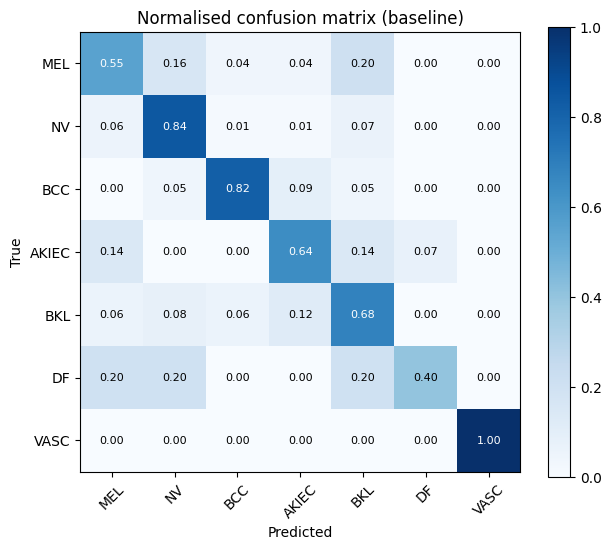

In [19]:
if not DEMO_MODE:   # training only (skipped when saved models are found)
    try:
        from sklearn.metrics import confusion_matrix
        cm = confusion_matrix(L, P, labels=list(range(N_CLS)))
        cmn = cm / np.maximum(cm.sum(1, keepdims=True), 1)
        plt.figure(figsize=(6.5, 5.5)); plt.imshow(cmn, cmap="Blues", vmin=0, vmax=1)
        plt.xticks(range(N_CLS), CLASS_NAMES, rotation=45); plt.yticks(range(N_CLS), CLASS_NAMES)
        for i in range(N_CLS):
            for j in range(N_CLS):
                plt.text(j, i, f"{cmn[i, j]:.2f}", ha="center", va="center", color="white" if cmn[i, j] > 0.5 else "black", fontsize=8)
        plt.title("Normalised confusion matrix (baseline)"); plt.xlabel("Predicted"); plt.ylabel("True"); plt.colorbar(); plt.tight_layout(); plt.show()
    except Exception as _e:
        print('This optional analysis step was skipped because of an error (the app is not affected):', repr(_e))

## 9. Explainable AI: Grad-CAM and the "does it look at the lesion?" metric

For every test image we compute a Grad-CAM heatmap for the predicted class, then compare it with the **ground-truth lesion mask** using:
- **Heatmap–mask IoU:** heatmap thresholded at 0.5 vs. the true mask.
- **Attention-in-lesion ratio:** share of total heatmap energy that falls inside the lesion. Compare it with the lesion's area fraction (what *random* attention would score). A ratio well above the area fraction means the model genuinely focuses on the lesion.

Mean heatmap-mask IoU          : 0.404
Mean attention-in-lesion ratio : 0.752
Mean lesion area fraction (chance level): 0.261

Per class:
         iou  attn_in_lesion  lesion_area
class                                    
AKIEC  0.260           0.827        0.555
BCC    0.353           0.658        0.247
BKL    0.337           0.722        0.281
DF     0.343           0.319        0.124
MEL    0.414           0.804        0.341
NV     0.423           0.769        0.239
VASC   0.487           0.327        0.049


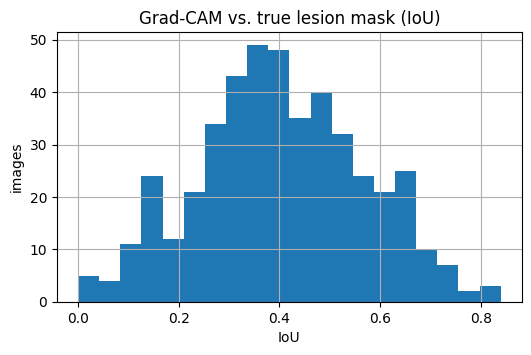

In [20]:
if not DEMO_MODE:   # training only (skipped when saved models are found)
    try:
        from pytorch_grad_cam import GradCAM
        from pytorch_grad_cam.utils.image import show_cam_on_image

        cam = GradCAM(model=cls_model, target_layers=[cls_model.net.features[-1]])

        rows, idx = [], 0
        for imgs, masks, labels in test_loader:
            hms = cam(input_tensor=imgs.to(DEVICE), targets=None)          # (B, H, W) in [0, 1]
            for i in range(len(hms)):
                h, g = hms[i], masks[i, 0].numpy()
                hb = (h >= 0.5).astype(np.float32)
                iou = float((hb * g).sum() / (np.clip(hb + g, 0, 1).sum() + 1e-8))
                rows.append({"idx": idx, "id": test_ds.ids[idx], "class": CLASS_NAMES[int(labels[i])],
                             "iou": iou, "attn_in_lesion": float((h * g).sum() / (h.sum() + 1e-8)),
                             "lesion_area": float(g.mean())})
                idx += 1

        xai_df = pd.DataFrame(rows)
        print(f"Mean heatmap-mask IoU          : {xai_df['iou'].mean():.3f}")
        print(f"Mean attention-in-lesion ratio : {xai_df['attn_in_lesion'].mean():.3f}")
        print(f"Mean lesion area fraction (chance level): {xai_df['lesion_area'].mean():.3f}")
        print("\nPer class:")
        print(xai_df.groupby("class")[["iou", "attn_in_lesion", "lesion_area"]].mean().round(3))

        plt.figure(figsize=(6, 3.5)); xai_df["iou"].hist(bins=20)
        plt.title("Grad-CAM vs. true lesion mask (IoU)"); plt.xlabel("IoU"); plt.ylabel("images"); plt.show()
    except Exception as _e:
        print('This optional analysis step was skipped because of an error (the app is not affected):', repr(_e))

### Qualitative gallery: best-aligned vs. worst-aligned explanations (honest failure analysis)

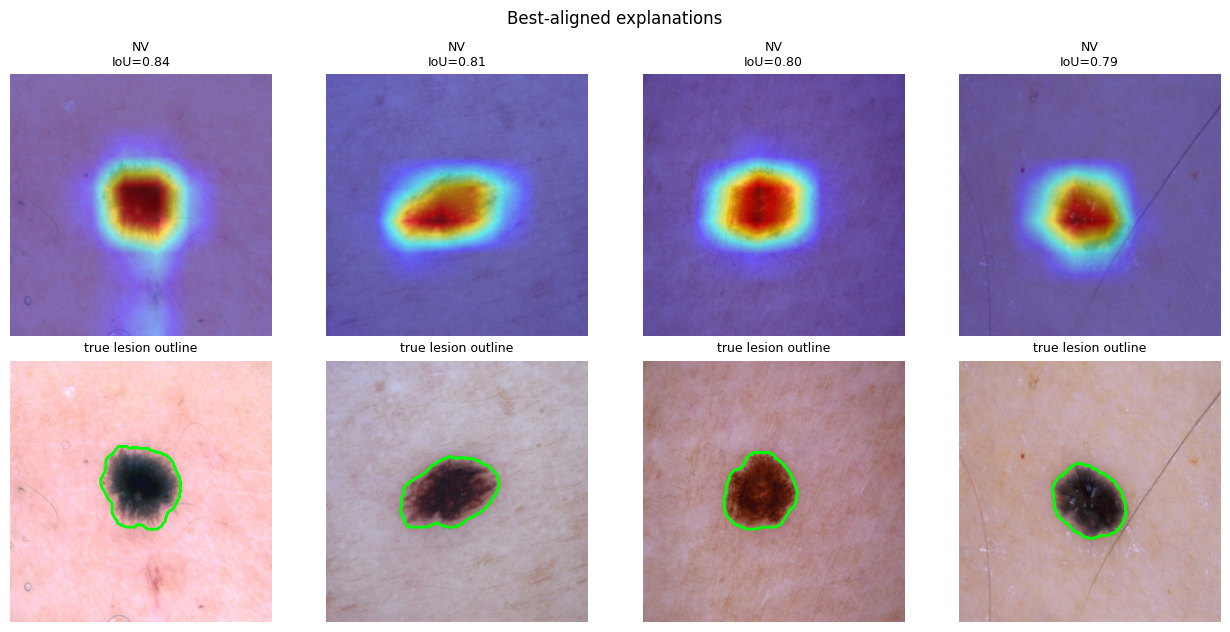

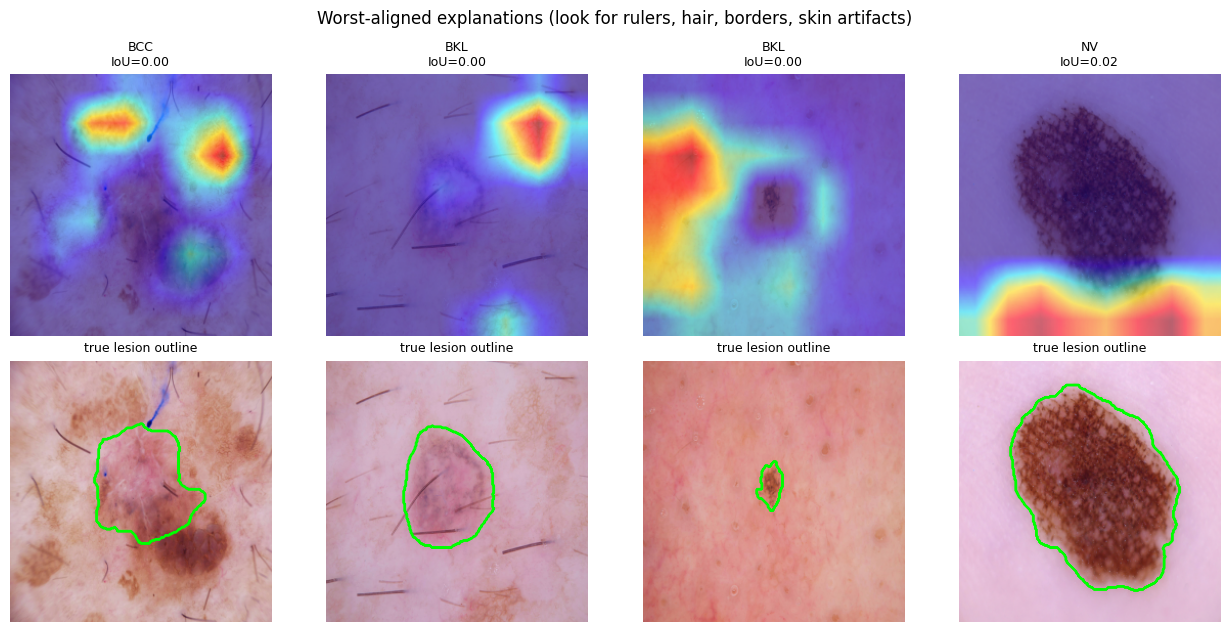

In [21]:
if not DEMO_MODE:   # training only (skipped when saved models are found)
    try:
        def show_cases(df_rows, title):
            fig, ax = plt.subplots(2, len(df_rows), figsize=(3.2 * len(df_rows), 6.4))
            for k, (_, row) in enumerate(df_rows.iterrows()):
                img, mask, lab = test_ds[int(row["idx"])]
                x = img.unsqueeze(0).to(DEVICE)
                h = cam(input_tensor=x, targets=None)[0]
                rgb = img.permute(1, 2, 0).numpy().astype(np.float32)
                ax[0, k].imshow(show_cam_on_image(rgb, h, use_rgb=True))
                ax[0, k].set_title(f"{row['class']}\nIoU={row['iou']:.2f}", fontsize=9)
                ax[1, k].imshow(rgb); ax[1, k].contour(mask[0].numpy(), colors="lime", linewidths=1.2)
                ax[1, k].set_title("true lesion outline", fontsize=9)
                ax[0, k].axis("off"); ax[1, k].axis("off")
            fig.suptitle(title); plt.tight_layout(); plt.show()

        show_cases(xai_df.sort_values("iou", ascending=False).head(4), "Best-aligned explanations")
        show_cases(xai_df.sort_values("iou").head(4), "Worst-aligned explanations (look for rulers, hair, borders, skin artifacts)")
    except Exception as _e:
        print('This optional analysis step was skipped because of an error (the app is not affected):', repr(_e))

## 9b. Load the trained models (tomorrow) / reuse the ones just trained (today)

In [22]:
if DEMO_MODE:
    # ---- tomorrow: load the models trained earlier ----
    if drive_has_models():
        WEIGHTS_DIR = DRIVE_FOLDER
        print("Loading your saved models from Google Drive:", DRIVE_FOLDER)
    else:
        print("Models not found on Drive. Select all 3 files from your computer:", ", ".join(NEEDED))
        from google.colab import files
        files.upload()
        missing = [f for f in NEEDED if not os.path.exists(f)]
        if missing:
            raise FileNotFoundError("Missing: " + ", ".join(missing) + ". Re-run this cell and select all three files.")
        WEIGHTS_DIR = "."

    with open(os.path.join(WEIGHTS_DIR, "model_meta.json")) as f:
        meta = json.load(f)
    CLASS_NAMES, IMG_SIZE = meta["class_names"], meta["img_size"]

    seg_model = UNet().to(DEVICE)
    seg_model.load_state_dict(torch.load(os.path.join(WEIGHTS_DIR, "unet_best.pt"), map_location=DEVICE))
    cls_model = SkinClassifier(len(CLASS_NAMES), pretrained=False).to(DEVICE)
    cls_model.load_state_dict(torch.load(os.path.join(WEIGHTS_DIR, "efficientnet_baseline_best.pt"), map_location=DEVICE))
    print("Models loaded. Classes:", CLASS_NAMES)

    summary_path = os.path.join(WEIGHTS_DIR, "results_summary.json")
    if os.path.exists(summary_path):
        print("\nResults from your training run:")
        print(json.dumps(json.load(open(summary_path)), indent=2))

seg_model.eval(); cls_model.eval()
N_CLS = len(CLASS_NAMES)

## 10. Single-image pipeline (this is what the web app calls)

In [23]:
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image

cam = GradCAM(model=cls_model, target_layers=[cls_model.net.features[-1]])

CLASS_FULL_NAMES = {
    "MEL": "Melanoma", "NV": "Melanocytic nevus", "BCC": "Basal cell carcinoma",
    "AKIEC": "Actinic keratosis / Bowen's", "BKL": "Benign keratosis", "DF": "Dermatofibroma",
    "VASC": "Vascular lesion",
}
def pretty(c): return CLASS_FULL_NAMES.get(str(c).upper().strip(), c)

def analyze(image_rgb):
    if image_rgb.ndim == 2:
        image_rgb = np.stack([image_rgb] * 3, -1)
    image_rgb = image_rgb[:, :, :3].astype(np.uint8)
    img = cv2.resize(image_rgb, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_AREA)
    x = (torch.from_numpy(img).permute(2, 0, 1).float() / 255.0).unsqueeze(0).to(DEVICE)

    seg_model.eval(); cls_model.eval()
    with torch.no_grad():
        mask = (torch.sigmoid(seg_model(x))[0, 0] > 0.5).cpu().numpy().astype(np.uint8)
        probs = F.softmax(cls_model(x), 1)[0].cpu().numpy()
    hm = cam(input_tensor=x, targets=None)[0]

    rgb = img.astype(np.float32) / 255.0
    seg_overlay = rgb.copy()
    seg_overlay[mask == 1] = 0.6 * seg_overlay[mask == 1] + 0.4 * np.array([0, 1, 0], dtype=np.float32)
    cnts, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    seg_overlay = (seg_overlay * 255).astype(np.uint8).copy()
    cv2.drawContours(seg_overlay, cnts, -1, (0, 255, 0), 2)

    inside = float((hm * mask).sum() / (hm.sum() + 1e-8))
    return {"probs": probs, "mask": mask, "seg_overlay": seg_overlay,
            "cam_overlay": show_cam_on_image(rgb, hm, use_rgb=True),
            "attn_in_lesion": inside, "lesion_frac": float(mask.mean())}

In [24]:
# Self-test: runs the whole pipeline once on a random image so any problem shows up HERE, not during your demo.
try:
    _t = analyze((np.random.rand(300, 300, 3) * 255).astype(np.uint8))
    print("PIPELINE SELF-TEST PASSED: segmentation + classification + Grad-CAM all work.")
except Exception as _e:
    import traceback; traceback.print_exc()
    print("PIPELINE SELF-TEST FAILED:", repr(_e))

PIPELINE SELF-TEST PASSED: segmentation + classification + Grad-CAM all work.


Prediction: Actinic keratosis / Bowen's (97.4%)  | true: Actinic keratosis / Bowen's


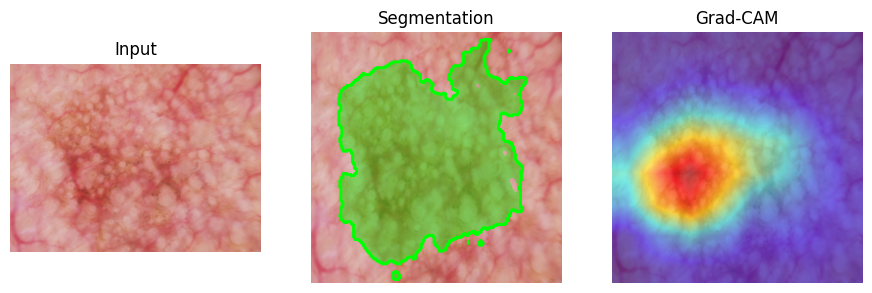

In [25]:
if not DEMO_MODE:   # training only (skipped when saved models are found)
    try:
        # quick check on a test image
        path = test_records[0]["image"]
        demo_img = cv2.cvtColor(cv2.imread(path), cv2.COLOR_BGR2RGB)
        r = analyze(demo_img)
        top = int(r["probs"].argmax())
        print("Prediction:", pretty(CLASS_NAMES[top]), f"({r['probs'][top]:.1%})  | true:", pretty(CLASS_NAMES[test_records[0]["label"]]))
        fig, ax = plt.subplots(1, 3, figsize=(11, 4))
        ax[0].imshow(demo_img); ax[0].set_title("Input"); ax[1].imshow(r["seg_overlay"]); ax[1].set_title("Segmentation"); ax[2].imshow(r["cam_overlay"]); ax[2].set_title("Grad-CAM")
        for a in ax: a.axis("off")
        plt.show()
    except Exception as _e:
        print('This optional analysis step was skipped because of an error (the app is not affected):', repr(_e))

## 11. Save models and a results summary (for your README / resume)

In [26]:
if not DEMO_MODE:   # training only (skipped when saved models are found)
    g = globals()
    summary = {"samples_used": len(records),
               "split": {"train": len(train_ds), "val": len(val_ds), "test": len(test_ds)},
               "classes": CLASS_NAMES}
    if "test_dice" in g:
        summary["segmentation_test"] = {"dice": float(test_dice), "iou": float(test_iou)}
    if "ablation" in g:
        summary["classification_test"] = ablation
    if "xai_df" in g:
        summary["explainability"] = {
            "mean_heatmap_mask_iou": float(xai_df["iou"].mean()),
            "mean_attention_in_lesion": float(xai_df["attn_in_lesion"].mean()),
            "mean_lesion_area_fraction_chance": float(xai_df["lesion_area"].mean()),
        }
    with open("results_summary.json", "w") as f:
        json.dump(summary, f, indent=2)
    print(json.dumps(summary, indent=2))

    with open("model_meta.json", "w") as f:
        json.dump({"class_names": CLASS_NAMES, "img_size": IMG_SIZE}, f)
    backup("unet_best.pt", "efficientnet_baseline_best.pt", "model_meta.json", "results_summary.json")

    # a few sample images, saved next to the models so tomorrow's demo has built-in examples
    if SAVE_TO_DRIVE and os.path.isdir(DRIVE_FOLDER):
        sd = os.path.join(DRIVE_FOLDER, "samples")
        os.makedirs(sd, exist_ok=True)
        for k, r_ in enumerate(test_records[:6]):
            shutil.copy(r_["image"], os.path.join(sd, f"example_{k+1}.jpg"))
        print("\nAll files are in your Google Drive folder: MyDrive/SkinLesionProject")
        print("Files there:", sorted(os.listdir(DRIVE_FOLDER)))

{
  "samples_used": 3000,
  "split": {
    "train": 2099,
    "val": 451,
    "test": 450
  },
  "classes": [
    "MEL",
    "NV",
    "BCC",
    "AKIEC",
    "BKL",
    "DF",
    "VASC"
  ],
  "segmentation_test": {
    "dice": 0.8972216248512268,
    "iou": 0.8316157994599178
  },
  "classification_test": {
    "baseline_full_image": {
      "accuracy": 0.7844444444444445,
      "macro_f1": 0.6591752330182301,
      "macro_auc": 0.9348890790061498
    },
    "mask_guided": {
      "accuracy": 0.6977777777777778,
      "macro_f1": 0.5475794174257135,
      "macro_auc": 0.9159663405689459
    }
  },
  "explainability": {
    "mean_heatmap_mask_iou": 0.40428527656528684,
    "mean_attention_in_lesion": 0.7519119942356418,
    "mean_lesion_area_fraction_chance": 0.2609381103515625
  }
}
  backed up to Drive: unet_best.pt
  backed up to Drive: efficientnet_baseline_best.pt
  backed up to Drive: model_meta.json
  backed up to Drive: results_summary.json

All files are in your Google Drive 

## 12. Web app (frontend)

Run the cell below. It prints a **public link** (`https://xxxx.gradio.live`) you can open on any device and share while this notebook is running.
Upload a lesion image (or use the camera) and you get the predicted class with probabilities, the lesion segmentation, and the Grad-CAM heatmap.

Keep this cell running while you use the app. Stopping it shuts the app down.

In [27]:
import gradio as gr

sample_paths = []
os.makedirs("samples", exist_ok=True)
if not DEMO_MODE:   # right after training: use images from the test set
    for k, r_ in enumerate(test_records[:4]):
        p = f"samples/example_{k+1}.jpg"
        shutil.copy(r_["image"], p); sample_paths.append([p])
else:               # tomorrow: use the sample images that were saved to Drive during training
    drive_samples = os.path.join(DRIVE_FOLDER, "samples")
    if os.path.isdir(drive_samples):
        for f_ in sorted(os.listdir(drive_samples))[:4]:
            if f_.lower().endswith((".jpg", ".jpeg", ".png")):
                p = os.path.join("samples", f_)
                shutil.copy(os.path.join(drive_samples, f_), p); sample_paths.append([p])

def gradio_predict(image):
    if image is None:
        return None, None, None, "Please upload an image first."
    try:
        res = analyze(image)
    except Exception as e:
        import traceback; traceback.print_exc()
        return None, None, None, f"Sorry, this image could not be analysed ({type(e).__name__}: {e})."
    probs = res["probs"]; top = int(probs.argmax())
    label_dict = {pretty(c): float(p) for c, p in zip(CLASS_NAMES, probs)}
    notes = [f"**Prediction:** {pretty(CLASS_NAMES[top])} ({probs[top]:.1%} confidence)"]
    if probs[top] < 0.5:
        notes.append("Low confidence: the model is unsure about this image.")
    if res["lesion_frac"] < 0.01:
        notes.append("No clear lesion was segmented. The image may not be a close-up of a skin lesion.")
    else:
        notes.append(f"**Attention check:** {res['attn_in_lesion']:.0%} of the model's attention fell inside the segmented lesion "
                     f"(the lesion covers {res['lesion_frac']:.0%} of the image).")
    notes.append("_Educational demo trained on dermoscopy images. Not a medical device and not a diagnosis. "
                 "Phone or webcam photos look different from the training data and will be less reliable. See a dermatologist for any skin concern._")
    return label_dict, res["seg_overlay"], res["cam_overlay"], "\n\n".join(notes)

with gr.Blocks(title="Skin Lesion Analysis") as demo:
    gr.Markdown("# Skin Lesion Analysis\nU-Net segmentation + EfficientNet classification + Grad-CAM explainability. **Educational use only.**")
    with gr.Row():
        inp = gr.Image(label="Lesion image", type="numpy", sources=["upload", "webcam"])
        out_label = gr.Label(label="Class probabilities", num_top_classes=N_CLS)
    with gr.Row():
        out_seg = gr.Image(label="Segmented lesion")
        out_cam = gr.Image(label="Grad-CAM (where the model looked)")
    out_txt = gr.Markdown()
    btn = gr.Button("Analyze", variant="primary")
    btn.click(gradio_predict, inputs=inp, outputs=[out_label, out_seg, out_cam, out_txt])
    if sample_paths:
        gr.Examples(examples=sample_paths, inputs=inp, label="Try a sample image")

demo.launch(share=True, debug=True)

Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://0631d11411a9ad23d4.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


Keyboard interruption in main thread... closing server.
Killing tunnel 127.0.0.1:7860 <> https://0631d11411a9ad23d4.gradio.live
